In [5]:
# Import needed packages
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.arima.model import ARIMA
import matplotlib.pyplot as plt


## MET forecast data

In [6]:
weather_forecast = pd.read_parquet('Wind_AI_data/met_forecast.parquet')

In [7]:
# Viiew model
weather_forecast

,sid,time_ref,time,lt,ws10m_00,ws10m_01,ws10m_02,ws10m_03,ws10m_04,ws10m_05,...,g10m_05,g10m_06,g10m_07,g10m_08,g10m_09,g10m_10,g10m_11,g10m_12,g10m_13,g10m_14
0,Engerfjellet,2020-02-15 12:00:00,2020-02-15 12:00:00,0,2.096957,2.110652,2.304629,1.942044,1.447011,2.288181,...,6.918935,8.110546,5.988888,6.934274,5.235212,5.507061,7.193576,6.753938,4.841811,4.875890
1,Engerfjellet,2020-02-15 12:00:00,2020-02-15 13:00:00,1,3.449402,3.436193,3.205872,3.450461,3.143307,4.278822,...,9.914339,9.184751,6.999992,7.892150,7.214608,8.252510,9.535547,8.717684,8.152432,6.240438
2,Engerfjellet,2020-02-15 12:00:00,2020-02-15 14:00:00,2,3.348926,2.903557,2.779971,3.733802,3.148597,2.912592,...,10.031385,8.624619,7.984353,8.264300,7.205638,9.052546,9.531441,8.367238,7.840395,7.153080
3,Engerfjellet,2020-02-15 12:00:00,2020-02-15 15:00:00,3,3.095971,2.560161,2.448126,2.267286,3.050008,3.310141,...,8.185250,8.821701,7.481009,8.172009,6.255360,7.345034,8.303812,6.735660,7.600200,7.189164
4,Engerfjellet,2020-02-15 12:00:00,2020-02-15 16:00:00,4,2.821545,2.965743,3.235484,3.212730,3.064931,2.420390,...,7.551644,9.709259,8.365305,8.703517,6.151643,10.116440,7.346225,9.079601,9.048587,6.937930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6874207,Hamnefjell,2025-03-15 09:00:00,2025-03-18 01:00:00,64,6.872266,7.164222,6.316023,5.589070,6.980499,4.612734,...,7.563049,8.551785,9.509587,9.794330,8.066090,8.411860,10.138005,2.795730,9.581801,7.873007
6874208,Hamnefjell,2025-03-16 09:00:00,2025-03-19 01:00:00,64,16.470940,16.099072,7.887674,14.270714,4.360876,10.369994,...,14.324461,30.275700,8.210348,18.635717,10.935499,18.720608,26.935497,6.617165,21.847015,31.888178
6874209,Hamnefjell,2025-03-22 09:00:00,2025-03-25 01:00:00,64,10.446624,9.178246,12.801767,9.458190,9.951641,8.660180,...,13.481665,18.230787,13.330455,16.758130,10.482368,10.948782,14.067688,15.863382,13.946945,12.476421
6874210,Hamnefjell,2025-03-23 09:00:00,2025-03-26 01:00:00,64,18.683716,16.797531,16.638610,16.367867,17.087458,13.853215,...,19.608253,25.046673,13.443735,19.931894,24.276434,25.254436,17.580925,24.548616,27.329407,19.575188


In [8]:
# Converting time to local time. We will use this to extract the 2-day ahead forecasts
weather_forecast['time'] = weather_forecast['time'].dt.tz_localize('UTC').dt.tz_convert('CET')
weather_forecast['time_ref'] = weather_forecast['time_ref'].dt.tz_localize('UTC').dt.tz_convert('CET')
weather_forecast

,sid,time_ref,time,lt,ws10m_00,ws10m_01,ws10m_02,ws10m_03,ws10m_04,ws10m_05,...,g10m_05,g10m_06,g10m_07,g10m_08,g10m_09,g10m_10,g10m_11,g10m_12,g10m_13,g10m_14
0,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 13:00:00+01:00,0,2.096957,2.110652,2.304629,1.942044,1.447011,2.288181,...,6.918935,8.110546,5.988888,6.934274,5.235212,5.507061,7.193576,6.753938,4.841811,4.875890
1,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 14:00:00+01:00,1,3.449402,3.436193,3.205872,3.450461,3.143307,4.278822,...,9.914339,9.184751,6.999992,7.892150,7.214608,8.252510,9.535547,8.717684,8.152432,6.240438
2,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 15:00:00+01:00,2,3.348926,2.903557,2.779971,3.733802,3.148597,2.912592,...,10.031385,8.624619,7.984353,8.264300,7.205638,9.052546,9.531441,8.367238,7.840395,7.153080
3,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 16:00:00+01:00,3,3.095971,2.560161,2.448126,2.267286,3.050008,3.310141,...,8.185250,8.821701,7.481009,8.172009,6.255360,7.345034,8.303812,6.735660,7.600200,7.189164
4,Engerfjellet,2020-02-15 13:00:00+01:00,2020-02-15 17:00:00+01:00,4,2.821545,2.965743,3.235484,3.212730,3.064931,2.420390,...,7.551644,9.709259,8.365305,8.703517,6.151643,10.116440,7.346225,9.079601,9.048587,6.937930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6874207,Hamnefjell,2025-03-15 10:00:00+01:00,2025-03-18 02:00:00+01:00,64,6.872266,7.164222,6.316023,5.589070,6.980499,4.612734,...,7.563049,8.551785,9.509587,9.794330,8.066090,8.411860,10.138005,2.795730,9.581801,7.873007
6874208,Hamnefjell,2025-03-16 10:00:00+01:00,2025-03-19 02:00:00+01:00,64,16.470940,16.099072,7.887674,14.270714,4.360876,10.369994,...,14.324461,30.275700,8.210348,18.635717,10.935499,18.720608,26.935497,6.617165,21.847015,31.888178
6874209,Hamnefjell,2025-03-22 10:00:00+01:00,2025-03-25 02:00:00+01:00,64,10.446624,9.178246,12.801767,9.458190,9.951641,8.660180,...,13.481665,18.230787,13.330455,16.758130,10.482368,10.948782,14.067688,15.863382,13.946945,12.476421
6874210,Hamnefjell,2025-03-23 10:00:00+01:00,2025-03-26 02:00:00+01:00,64,18.683716,16.797531,16.638610,16.367867,17.087458,13.853215,...,19.608253,25.046673,13.443735,19.931894,24.276434,25.254436,17.580925,24.548616,27.329407,19.575188


In [9]:
# how many unique names 
weather_forecast["sid"].nunique()

61

In [10]:
# The observed weather
weather_nowcast = pd.read_parquet("Wind_AI_data/met_nowcast.parquet")
weather_nowcast = weather_nowcast.tz_localize('UTC').tz_convert('CET') # Converting to local time
weather_nowcast

,air_temperature_2m,air_pressure_at_sea_level,relative_humidity_2m,precipitation_amount,wind_speed_10m,wind_direction_10m,windpark
time,,,,,,,
2020-01-01 01:00:00+01:00,276.363831,100703.859375,0.966131,3.147963,13.445930,250.681976,Bessakerfjellet
2020-01-01 02:00:00+01:00,276.951080,100595.609375,0.972677,3.636308,13.807796,251.660736,Bessakerfjellet
2020-01-01 03:00:00+01:00,277.113007,100526.656250,0.964682,1.921109,15.788631,250.626617,Bessakerfjellet
2020-01-01 04:00:00+01:00,277.259033,100408.359375,0.966498,1.919362,16.493980,254.728180,Bessakerfjellet
2020-01-01 05:00:00+01:00,277.229248,100421.062500,0.964835,1.275917,16.933884,253.571869,Bessakerfjellet
...,...,...,...,...,...,...,...
2025-03-31 21:00:00+02:00,271.956329,101966.796875,0.962775,1.563930,8.735393,196.803040,Øyfjell2
2025-03-31 22:00:00+02:00,271.778442,101946.859375,0.995688,0.375011,11.672383,206.363098,Øyfjell2
2025-03-31 23:00:00+02:00,271.601746,101986.929688,0.993568,0.034405,10.683748,209.511871,Øyfjell2


In [11]:
weather_nowcast["windpark"].nunique()

61

# Statnett Windpower Data

In [12]:
windpower = pd.read_parquet('Wind_AI_data/wind_power_per_bidzone.parquet')
windpower = windpower.tz_localize('UTC').tz_convert('CET')
windpower

,ELSPOT NO1,ELSPOT NO2,ELSPOT NO3,ELSPOT NO4
2020-01-01 01:00:00+01:00,149.285262,434.753864,497.143482,152.830002
2020-01-01 02:00:00+01:00,152.634024,395.572485,471.916899,144.440344
2020-01-01 03:00:00+01:00,151.163256,355.408523,399.325698,143.960894
2020-01-01 04:00:00+01:00,150.223341,375.316902,367.662849,134.310523
2020-01-01 05:00:00+01:00,157.415142,412.949107,399.627337,88.573315
...,...,...,...,...
2025-04-03 06:00:00+02:00,201.955371,69.323135,1483.929389,538.367662
2025-04-03 07:00:00+02:00,192.814220,69.898523,1536.323708,557.699333
2025-04-03 08:00:00+02:00,167.243268,92.504962,1475.358275,614.977323
2025-04-03 09:00:00+02:00,149.052714,84.891532,1438.855508,546.634438


# Statnett Windpark Metadata

In [13]:
windparks = pd.read_csv("Wind_AI_data/windparks_bidzone.csv")
windparks

,bidding_area,substation_name,operating_power_max,prod_start_new,eic_code
0,ELSPOT NO1,Engerfjellet,52.8,2022-09-19 13:00:00,50WP00000002158R
1,ELSPOT NO1,Hån Vindpark,21.0,2022-10-26 22:00:00,50WP000000022251
2,ELSPOT NO1,Kjølberget,55.9,2020-07-07 09:00:00,50WP00000002085S
3,ELSPOT NO1,Marker Vindpark,54.0,2020-01-01 00:00:00,50WP00000002048Y
4,ELSPOT NO1,Raskiftet,111.6,2020-01-01 00:00:00,50WP00000001718K
...,...,...,...,...,...
71,ELSPOT NO4,Raudfjell Vindpark,84.0,2020-08-31 15:00:00,50WP00000001897V
72,ELSPOT NO4,Sørfj. Vindkraft,96.6,2020-01-01 00:00:00,50WP00000001770I
73,ELSPOT NO4,Ånstadblåheia,50.4,2020-01-01 00:00:00,50WP00000001916G
74,ELSPOT NO4,Øyfjell1,172.6,2021-08-23 11:00:00,50WP000000021352


In [14]:
windparks["substation_name"].nunique()

65

In [15]:
windparks["bidding_area"].nunique()

4

# Extracting the data for each bidding zone

In [16]:
def extract_bidzone_data(windparks, windpower, weather_nowcast, bid_zones):
    """
    Extracts and prepares combined wind power and weather data for multiple bid zones.

    For each bid zone provided, this function:
    - Selects the relevant windparks from the metadata.
    - Retrieves the corresponding wind power time series.
    - Aggregates weather nowcast data by averaging across windparks in the zone.
    - Merges wind power and weather data into a single DataFrame.
    - Filters out time periods before all windparks in the zone became operational.

    Parameters:
    ----------
    windparks : pd.DataFrame
        Metadata about windparks, including 'bidding_area', 'substation_name', and 'prod_start_new'.
    
    windpower : dict of pd.DataFrame
        Dictionary where keys are bid zone names and values are wind power time series DataFrames.
    
    weather_nowcast : pd.DataFrame
        Weather data including 'windpark' and 'time' columns, with observations for each windpark.
    
    bid_zones : list of str
        List of bid zone names to process.

    Returns:
    -------
    dict
        A dictionary where each key is a bid zone name and each value is a DataFrame containing
        the combined wind power and averaged weather data for that zone.
    """

    bidzone_data_dict = {}

    for bid_zone in bid_zones:
        # Select windparks in the bid zone
        _windparks_in_bid_zone = windparks[windparks['bidding_area'] == bid_zone]

        # Select windpower data for the bid zone
        _windpower_in_bid_zone = windpower[bid_zone]

        # Calculate mean observed weather for windparks in the bid zone
        _weather_nowcast_in_bid_zone = weather_nowcast[
            weather_nowcast['windpark'].isin(_windparks_in_bid_zone['substation_name'])
        ].drop('windpark', axis=1).groupby('time').mean()

        # Concatenate weather and power data
        data_bidzone = pd.concat([_windpower_in_bid_zone, _weather_nowcast_in_bid_zone], axis=1)

        # Filter out data where not all windparks are operational
        data_bidzone = data_bidzone.loc[_windparks_in_bid_zone['prod_start_new'].max():].dropna()

        # Store result
        bidzone_data_dict[bid_zone] = data_bidzone

    return bidzone_data_dict


In [17]:
bid_zones = ['ELSPOT NO1', 'ELSPOT NO2', 'ELSPOT NO3', 'ELSPOT NO4']
bidzone_data = extract_bidzone_data(windparks, windpower, weather_nowcast, bid_zones)
bidzone_data

{'ELSPOT NO1':                            ELSPOT NO1  air_temperature_2m  \
 2022-10-26 22:00:00+02:00  122.875961          277.943146   
 2022-10-26 23:00:00+02:00  176.741970          278.011749   
 2022-10-27 00:00:00+02:00  157.861445          278.195679   
 2022-10-27 01:00:00+02:00  157.826574          278.405060   
 2022-10-27 02:00:00+02:00  157.826574          278.748596   
 ...                               ...                 ...   
 2025-03-31 21:00:00+02:00   41.568499          276.445709   
 2025-03-31 22:00:00+02:00   92.545477          275.382568   
 2025-03-31 23:00:00+02:00   79.970654          274.374878   
 2025-04-01 00:00:00+02:00   60.546669          273.695282   
 2025-04-01 01:00:00+02:00   63.157050          273.025116   
 
                            air_pressure_at_sea_level  relative_humidity_2m  \
 2022-10-26 22:00:00+02:00              101477.101562              0.991925   
 2022-10-26 23:00:00+02:00              101526.679688              0.998443   
 20

In [18]:
def split_bidzone_data(data_dict, train_ratio=0.8):
    """
    Splits each DataFrame in a dictionary into training and testing sets.

    Parameters:
    ----------
    data_dict : dict
        Dictionary where each key is a bid zone name and each value is a DataFrame of combined data.
    train_ratio : float, optional
        Proportion of data to use for training (default is 0.8).

    Returns:
    -------
    dict
        Dictionary with the same bid zone keys, each containing a sub-dictionary with 'train' and 'test' DataFrames.
    """
    split_data = {}

    for zone, df in data_dict.items():
        split_index = int(len(df) * train_ratio)
        train_df = df.iloc[:split_index]
        test_df = df.iloc[split_index:]
        split_data[zone] = {
            'train': train_df,
            'test': test_df
        }

    return split_data


In [19]:
split_result = split_bidzone_data(bidzone_data)

# View split sizes
for zone, sets in split_result.items():
    print(f"{zone}: Train={len(sets['train'])}, Test={len(sets['test'])}")


ELSPOT NO1: Train=17032, Test=4259
ELSPOT NO2: Train=3899, Test=975
ELSPOT NO3: Train=17309, Test=4328
ELSPOT NO4: Train=16384, Test=4097


In [20]:


def build_stacked_hybrid_model(split_data_dict):
    """
    Builds a hybrid stacked model for each bid zone to predict 'wind_speed_10m'.
    Combines ARIMA (statistical model) and Random Forest (machine learning model)
    using Linear Regression as a meta-model.

    Parameters:
    ----------
    split_data_dict : dict
        Dictionary with bid zone keys, each containing 'train' and 'test' DataFrames.

    Returns:
    -------
    dict
        Dictionary with bid zone keys and predicted values from the stacked model.
        Each entry includes:
            - 'actual': true values from the test set
            - 'arima': ARIMA predictions
            - 'rf': Random Forest predictions
            - 'stacked': final stacked predictions
            - 'mae_arima': MAE of ARIMA
            - 'mae_rf': MAE of Random Forest
            - 'mae_stacked': MAE of stacked model
    """
    predictions = {}

    for zone, data in split_data_dict.items():
        train_df = data['train']
        test_df = data['test']
        
        # Ensure the training DataFrame has a datetime index with hourly frequency
       # train_df.index = pd.date_range(start=train_df.index[0], periods=len(train_df), freq='H')


        # Define target and predictors
        y_train = train_df['wind_speed_10m']
       # y_train.index = y_train.index.to_period('H')

        X_train = train_df.drop(columns=['wind_speed_10m'])
        X_test = test_df.drop(columns=['wind_speed_10m'])
        y_test = test_df['wind_speed_10m']

        # ARIMA model
        try:
            arima_model = ARIMA(y_train, order=(2, 0, 2)).fit()
            arima_train_pred = arima_model.fittedvalues
            arima_test_pred = arima_model.forecast(steps=len(y_test))
        except Exception as e:
            print(f"ARIMA failed for {zone}: {e}")
            continue

        # Random Forest model
        rf_model = RandomForestRegressor()
        rf_model.fit(X_train, y_train)
        rf_train_pred = rf_model.predict(X_train)
        rf_test_pred = rf_model.predict(X_test)

        # Meta-model: Linear Regression
        meta_train = pd.DataFrame({
            'arima': arima_train_pred,
            'rf': rf_train_pred
        })
        meta_model = LinearRegression()
        meta_model.fit(meta_train, y_train)

        meta_test = pd.DataFrame({
            'arima': arima_test_pred,
            'rf': rf_test_pred
        })
        stacked_pred = meta_model.predict(meta_test)

        # Store predictions and errors
        predictions[zone] = {
            'actual': y_test.values,
            'arima': arima_test_pred,
            'rf': rf_test_pred,
            'stacked': stacked_pred,
            'mae_arima': mean_absolute_error(y_test, arima_test_pred),
            'mae_rf': mean_absolute_error(y_test, rf_test_pred),
            'mae_stacked': mean_absolute_error(y_test, stacked_pred)
        }

    return predictions


In [21]:
results = build_stacked_hybrid_model(split_result)

C:\Users\chidimmpe\AppData\Local\anaconda\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\chidimmpe\AppData\Local\anaconda\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\chidimmpe\AppData\Local\anaconda\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\chidimmpe\AppData\Local\anaconda\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an int

In [22]:
def visualize_predictions(results):
    """
    Visualizes actual vs predicted wind speed for each bid zone using line plots.

    Parameters:
    ----------
    results : dict
        Dictionary containing actual and predicted values for each bid zone.
        Each entry should include 'actual', 'arima', 'rf', and 'stacked' arrays.
    """
    for zone, res in results.items():
        plt.figure(figsize=(12, 4))
        plt.plot(res['actual'], label='Actual', color='black', marker='o')
        plt.plot(res['arima'], label='ARIMA', linestyle='--', color='blue')
        plt.plot(res['rf'], label='Random Forest', linestyle='--', color='green')
        plt.plot(res['stacked'], label='Stacked Model', linestyle='-', color='red')
        plt.title(f'Wind Speed Prediction - {zone}')
        plt.xlabel('Time Step')
        plt.ylabel('Wind Speed (10m)')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()


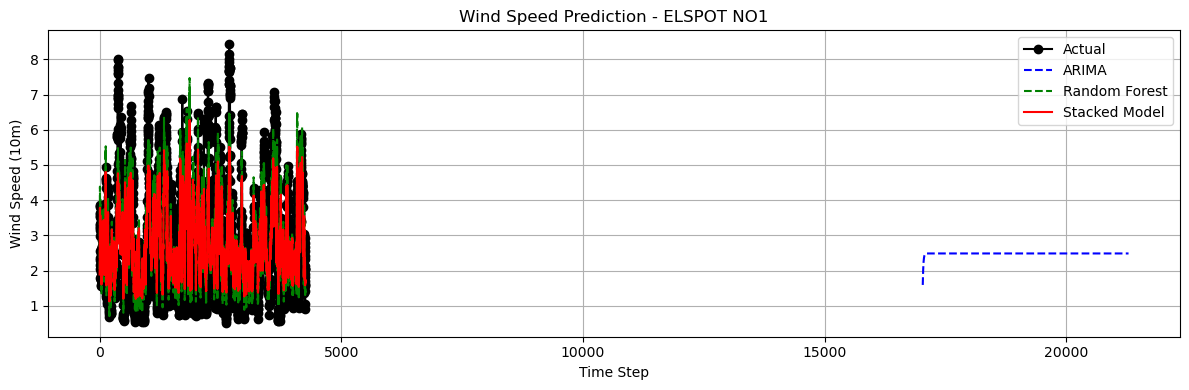

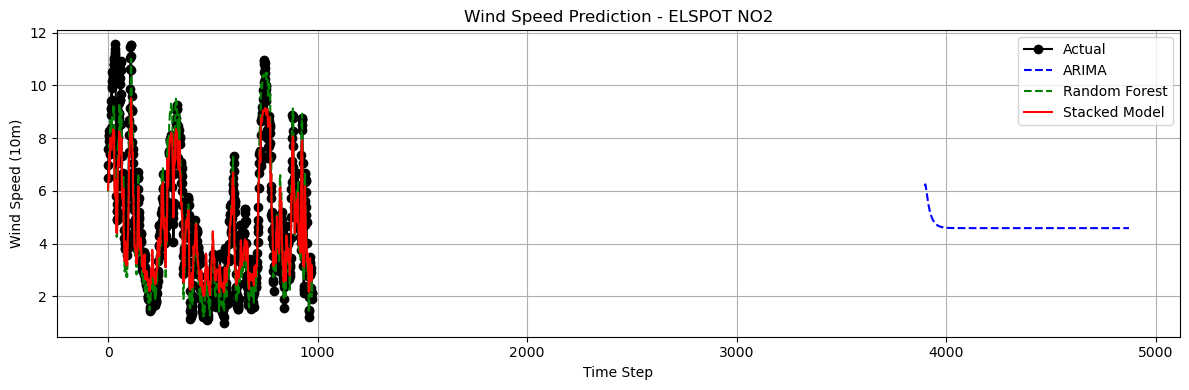

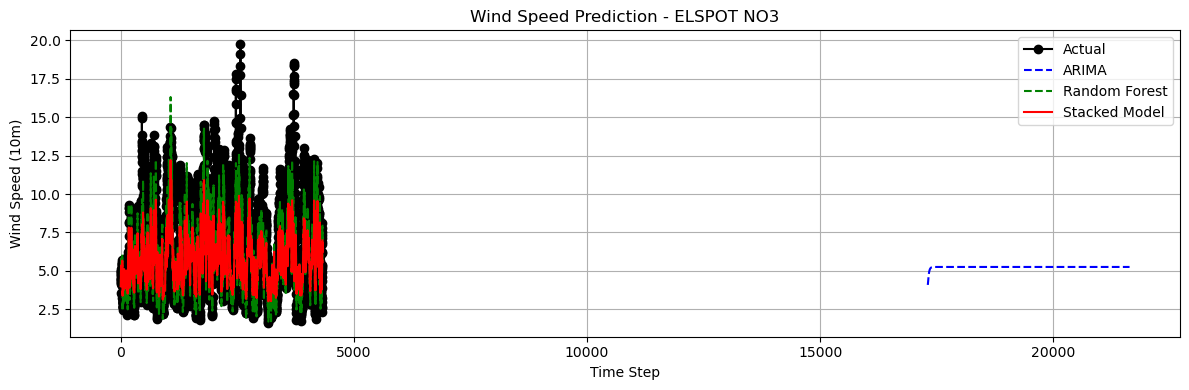

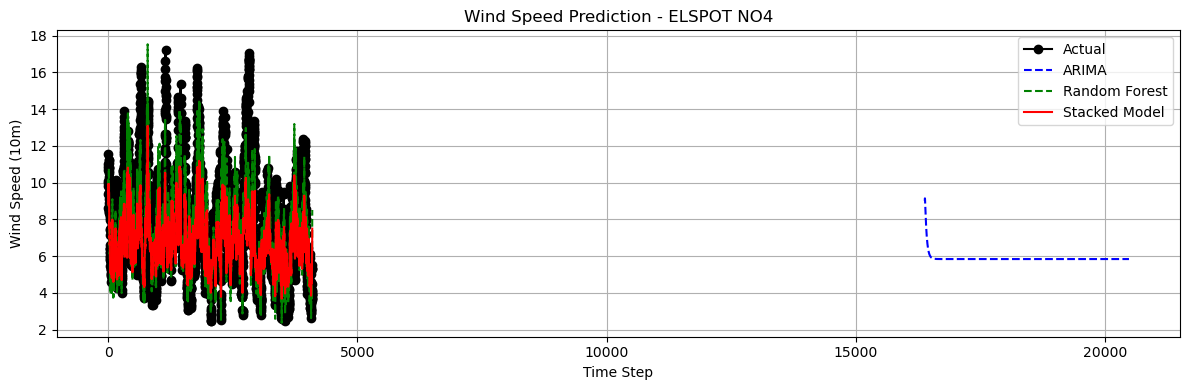

In [23]:
visualize_predictions(results)
